# Attention：找到被标记的数字

每个序列有四个位置，每个位置是 `[数值, 标记]`。只有一处标记为 1，目标就是那个位置的数值。
模型通过 `softmax(Q @ Kᵀ / √d) @ V` 学习从哪里读取信息。

In [9]:
from random import uniform, randrange
from qutai import nn, visualization

## 1. 准备序列

训练与测试使用不同种子生成。下面的表格中，标记为 1 的那行给出了正确答案。

In [10]:
def make_data():
    inputs, targets = [], []
    for _ in range(64):
        values = [uniform(-1, 1) for _ in range(4)]
        marked = randrange(4)
        inputs.append([[value, int(index == marked)] for index, value in enumerate(values)])
        targets.append([values[marked]])
    return inputs, targets

inputs, targets = make_data()
test_inputs, test_targets = make_data()
print("第一个序列的目标：", targets[0])
visualization.Table(inputs[0], columns=["数值", "标记"])

第一个序列的目标： [0.6317806710999025]


数值,标记
0.3221265586299211,0
-0.12914908719943785,0
-0.5107138264746633,0
0.6317806710999025,1


## 2. 搭建模型

Attention 将每个位置变成 8 个特征，Linear 输出一个数，Mean 再对四个位置取平均。
因此模型直接返回每个序列的一个预测，形状为 `(批次, 1)`。

In [12]:
model = nn.Model([
    nn.Attention(2, 8, seed=42),
    nn.Linear(8, 1, seed=43),
    nn.Mean(axis=1),
])
optimizer = nn.SGD(model, learning_rate=0.1, momentum=0.9)
loss_function = nn.MSE()
# visualization.Network(model)

## 3. 先看注意力，再训练

热图每一行代表一个查询位置，每一列代表被读取的位置；每行权重之和为 1。
在列名中标出目标位置，训练后再看同一个序列。

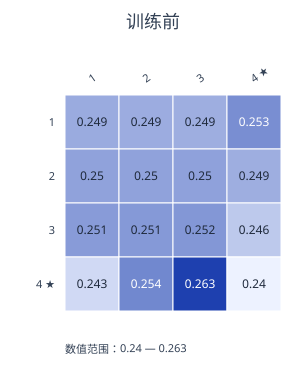

In [13]:
sample = inputs[:1]
attention = model.layers[0]
positions = [f"{index + 1}" + (" ★" if token[1] else "") for index, token in enumerate(sample[0])]
visualization.Heatmap(attention.weights(sample)[0].tolist(), xlabels=positions, ylabels=positions, title="训练前")

In [14]:
for step in range(401):
    optimizer.zero_grad()
    loss = loss_function(model(inputs), targets)
    loss.backward()
    optimizer.step()
    if step % 100 == 0:
        print(f"step {step}  MSE {loss.item():.6f}")

step 0  MSE 0.372930
step 100  MSE 0.000871
step 200  MSE 0.000431
step 300  MSE 0.000283
step 400  MSE 0.000208


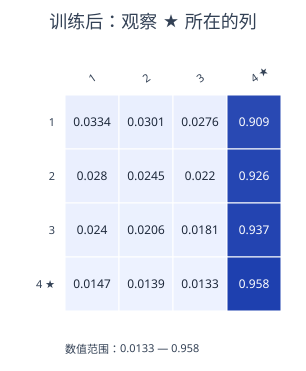

In [15]:
visualization.Heatmap(attention.weights(sample)[0].tolist(), xlabels=positions, ylabels=positions, title="训练后：观察 ★ 所在的列")

## 4. 在新序列上检查预测

测试目标仍是被标记的数值。这里只打印独立测试 MSE，并对照前八个预测。

In [16]:
predictions = model(test_inputs, train=False)
print("测试 MSE：", loss_function(predictions, test_targets).item())
visualization.Table(list(zip([row[0] for row in test_targets[:8]], [row[0] for row in predictions.tolist()[:8]])), columns=["正确数值", "预测数值"])

测试 MSE： 0.0001555275538690012


正确数值,预测数值
-0.5714355781431086,-0.518017689152331
0.10742950166767606,0.10676037168159089
-0.6082903882394219,-0.6001657749146608
0.39442122123615686,0.3915397343504365
-0.5728575229655242,-0.5812594579338578
0.8063308688521009,0.8130607056776709
-0.6490477653329076,-0.6425513848978246
0.8990318161513731,0.8920801965701127
